# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Olivia Teng, Ali Powell, Will Sutton"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

* Because we have 8 input features and want to measure a numerical outcome, compressive strength, we should first maybe look at summary stats. This would include things like count, mean, std, min, and max for each variable. It could also be helpful to check for missing values. histograms could also helps us examine the distributions of the inputs and strength, like skewness and weird values. Scatter plots could help us go a step further, and plot inputs against strength to look for increasing/decreasing/flat trends. A heatmap could be helpful to also see other relationships between variables. 

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

* First and foremost, we will start by cleaning the data, checking for missing values, looking at data types, etc. The inputs use different scales, which can make neural network optimization harder, so we need to standardize the features,and then after that convert the NNs inputs and targets into floating point Pytorch tensors. It is important that preprocessing happens separately inside each cross-validation fold. We will fit a new scaler on that fold's training observations, then use it to transform both the training and validation observations. Any imputations would follow the same rules. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

* Compressive strength is a continuous outcome we will treat this as a regression problem and use MSE as the neural networks cost function. MSE penalizes larger prediction errors more heavily. The output layer will have one unit with no additional activation function, allowing it to predict a continuous strength value. We can go and use ReLU in the hidden layers to model nonlinear relationships. 

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

* We will use shuffled five fold cross validation with a fixed random seed and the same folds for all 3 models. Each model will train on 4 folds and be evaluated on the remaining fold repeating until every fold has served as the validation set. We will fit preprocessing and initialize a fresh model within each fold, then calculate validation MSE and RMSE. We will report the mean and standard deviation of each metric across the five folds with lower error indicating better predictive performance.

USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

concrete = pd.read_excel("Concrete_Data.xls")
concrete.columns = concrete.columns.str.strip()

print(concrete.describe())

feature_names = concrete.columns[:-1].tolist()
target_name = concrete.columns[-1]
# Keep the original data for descriptive analysis, but remove exact duplicates
# before creating modeling inputs so identical records cannot cross folds.
modeling_data = concrete.drop_duplicates().reset_index(drop=True)
print("Exact duplicates removed for modeling:", len(concrete) - len(modeling_data))
X = modeling_data[feature_names].to_numpy(dtype=np.float32)
y = modeling_data[target_name].to_numpy(dtype=np.float32)

print("Dataset shape-", concrete.shape)
print("Missing values-", concrete.isna().sum().sum())
print("Input shape-", X.shape, "Target shape:", y.shape)
display(concrete.head())


       Cement (component 1)(kg in a m^3 mixture)  \
count                                1030.000000   
mean                                  281.165631   
std                                   104.507142   
min                                   102.000000   
25%                                   192.375000   
50%                                   272.900000   
75%                                   350.000000   
max                                   540.000000   

       Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
count                                        1030.000000       
mean                                           73.895485       
std                                            86.279104       
min                                             0.000000       
25%                                             0.000000       
50%                                            22.000000       
75%                                           142.950000       
max                

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [2]:
import matplotlib.pyplot as plt

# Missing values and data types
display(concrete.dtypes.to_frame("dtype").T)
print("Missing values per column:")
print(concrete.isna().sum())
print("Duplicate rows-", concrete.duplicated().sum())

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
dtype,float64,float64,float64,float64,float64,float64,float64,int64,float64


Missing values per column:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64
Duplicate rows- 25


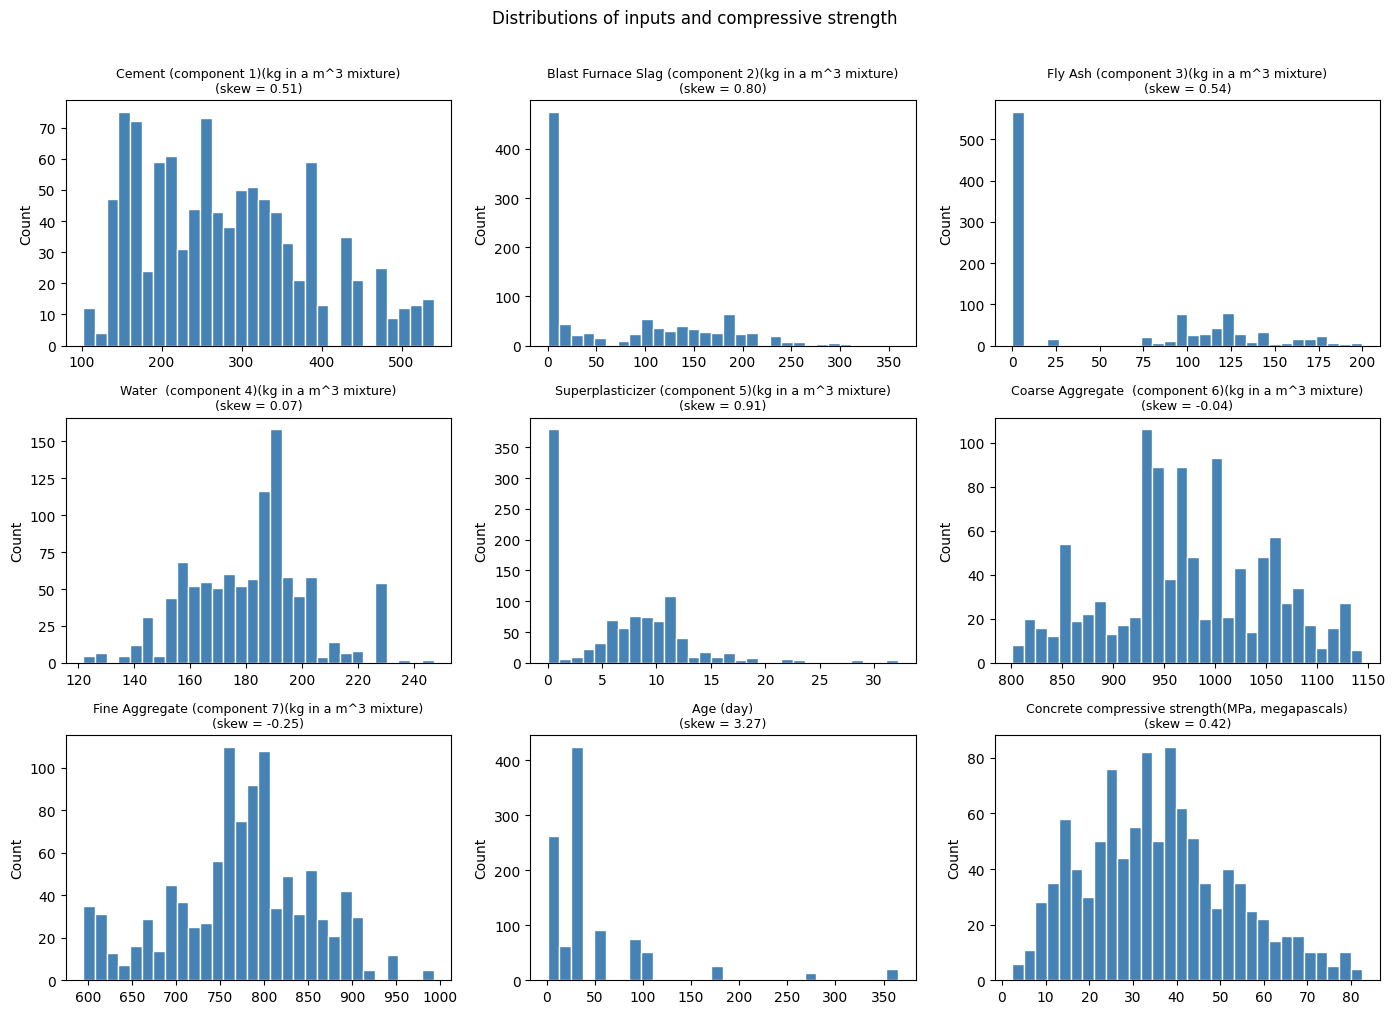

In [3]:
# Distributions histograms
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), concrete.columns):
    ax.hist(concrete[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(f"{col}\n(skew = {concrete[col].skew():.2f})", fontsize=9)
    ax.set_ylabel("Count")
plt.suptitle("Distributions of inputs and compressive strength", y=1.01)
plt.tight_layout()
plt.show()

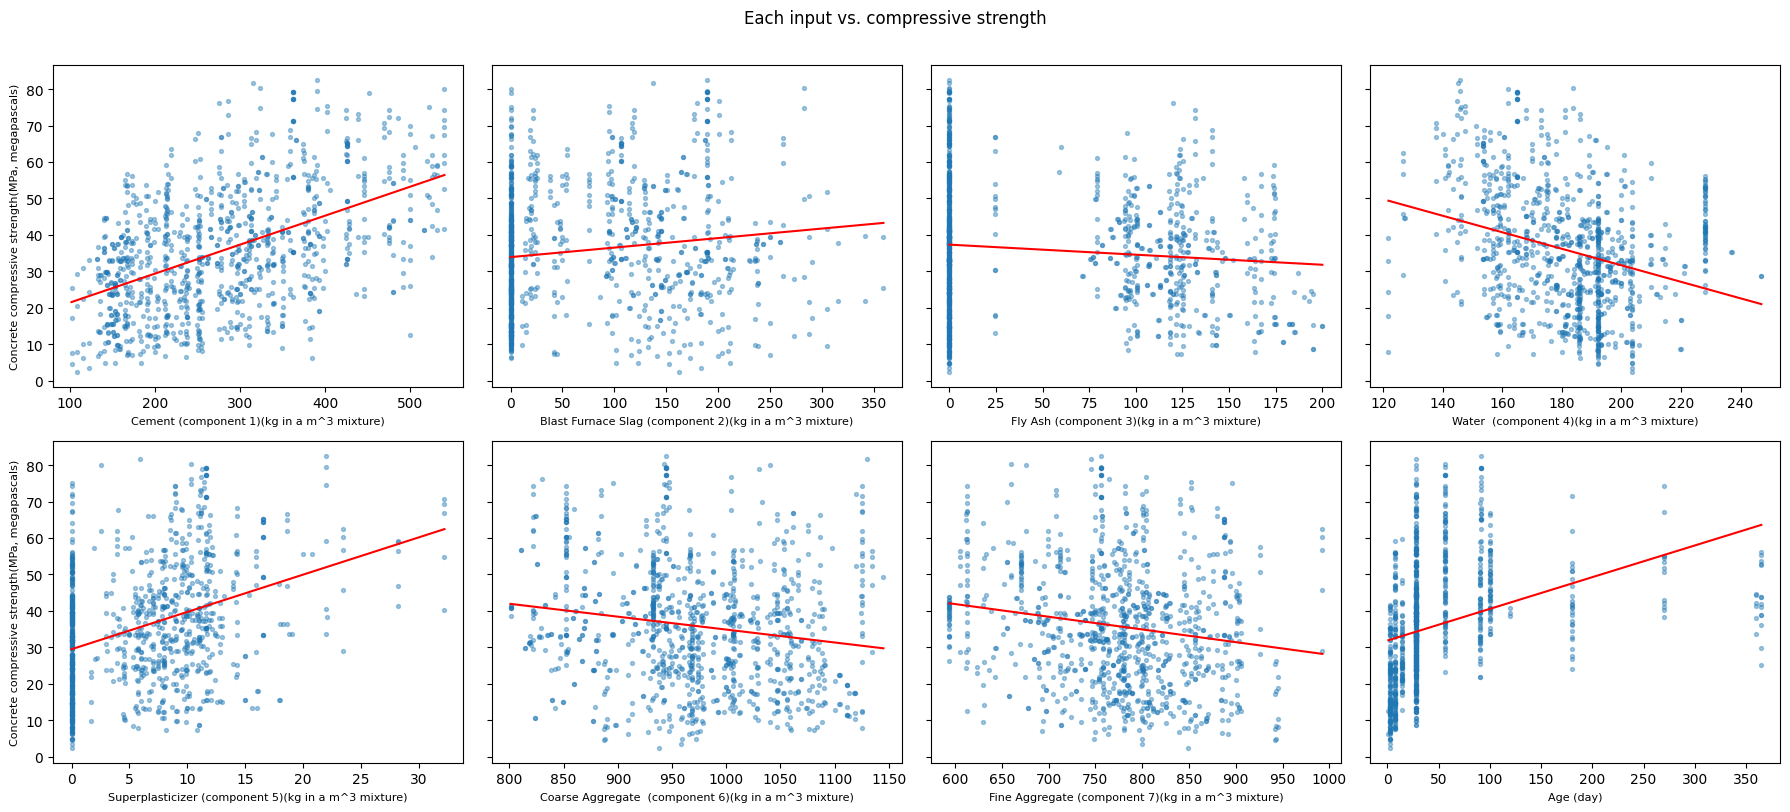

In [4]:
# Scatterplots
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, col in zip(axes.ravel(), feature_names):
    ax.scatter(concrete[col], concrete[target_name], s=8, alpha=0.4)
    slope, intercept = np.polyfit(concrete[col], concrete[target_name], 1)
    xs = np.linspace(concrete[col].min(), concrete[col].max(), 100)
    ax.plot(xs, slope * xs + intercept, color="red", linewidth=1.5)
    ax.set_xlabel(col, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel(target_name, fontsize=8)
plt.suptitle("Each input vs. compressive strength", y=1.01)
plt.tight_layout()
plt.show()

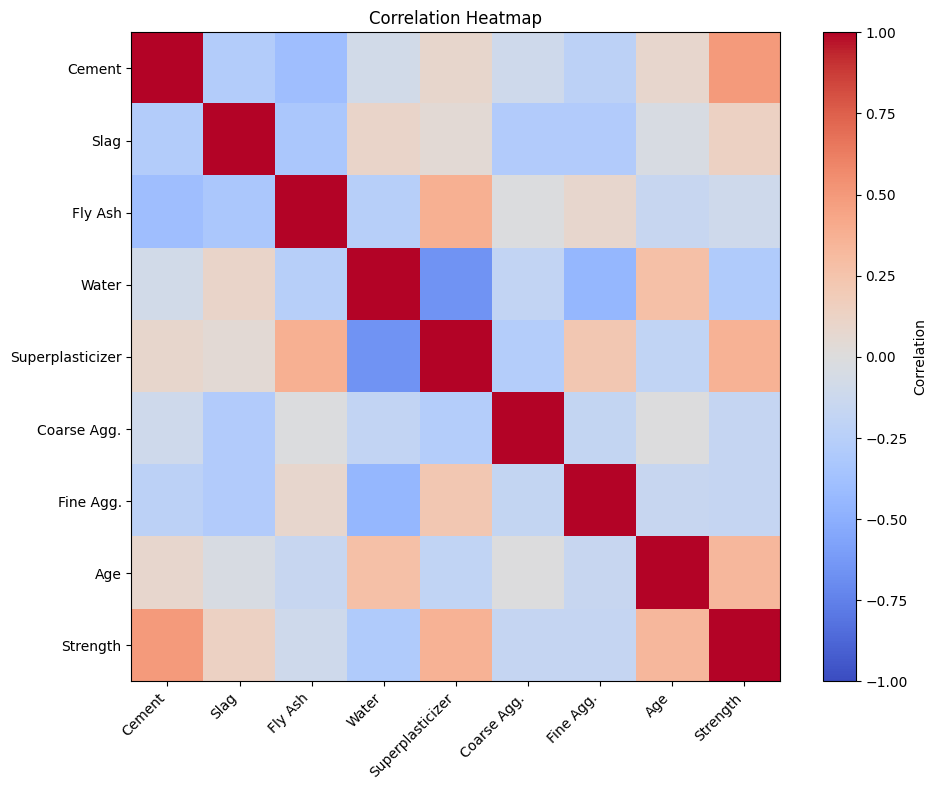

In [5]:
# Correlation heatmap
corr = concrete.corr()

labels = [
    "Cement", "Slag", "Fly Ash", "Water",
    "Superplasticizer", "Coarse Agg.",
    "Fine Agg.", "Age", "Strength"
]

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
plt.yticks(range(len(labels)), labels)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [6]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Fixed choices made before evaluation; no hyperparameter search
NN_HIDDEN_UNITS = (32, 16)
NN_LEARNING_RATE = 0.001
NN_EPOCHS = 200
NN_BATCH_SIZE = 32

# Reuse these exact splits for the models in parts 4 and 5
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(cv.split(X))

class ConcreteMLP(nn.Module):
    def __init__(self, input_size=8, hidden_units=NN_HIDDEN_UNITS):
        super().__init__()
        layers = []
        previous_size = input_size

        for units in hidden_units:
            layers.extend([nn.Linear(previous_size, units), nn.ReLU()])
            previous_size = units

        # One continuous strength prediction; no output activation
        layers.append(nn.Linear(previous_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, X):
        return self.network(X)

    def fit(self, X_train, y_train, X_validation, y_validation,
            learning_rate=NN_LEARNING_RATE, epochs=NN_EPOCHS,
            batch_size=NN_BATCH_SIZE, seed=42):
        loader = DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(seed)
        )
        loss_function = nn.MSELoss()
        optimizer = torch.optim.Adam(self.parameters(), lr=learning_rate)
        self.history = {"train_mse": [], "validation_mse": []}

        for epoch in range(epochs):
            self.train()
            for X_batch, y_batch in loader:
                optimizer.zero_grad()
                predictions = self(X_batch)
                loss = loss_function(predictions, y_batch)
                loss.backward()
                optimizer.step()

            # Monitor validation performance without using it for updates
            self.eval()
            with torch.no_grad():
                self.history["train_mse"].append(
                    loss_function(self(X_train), y_train).item()
                )
                self.history["validation_mse"].append(
                    loss_function(self(X_validation), y_validation).item()
                )

        return self

    def predict(self, X):
        self.eval()
        with torch.no_grad():
            return self(X).squeeze(1).numpy()


In [7]:
# Train a fresh network on each fold using the same fixed configuration
nn_results = []
nn_models = []
nn_scalers = []

for fold, (train_indices, validation_indices) in enumerate(cv_splits, start=1):
    # Fit only on this fold's training rows to prevent leakage
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X[train_indices])
    X_validation_scaled = scaler.transform(X[validation_indices])

    X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
    X_validation_t = torch.tensor(X_validation_scaled, dtype=torch.float32)
    y_train_t = torch.tensor(y[train_indices], dtype=torch.float32).reshape(-1, 1)
    y_validation_t = torch.tensor(
        y[validation_indices], dtype=torch.float32
    ).reshape(-1, 1)

    torch.manual_seed(42)
    model = ConcreteMLP(input_size=X.shape[1])
    model.fit(X_train_t, y_train_t, X_validation_t, y_validation_t)

    train_predictions = model.predict(X_train_t)
    validation_predictions = model.predict(X_validation_t)
    train_mse = mean_squared_error(y[train_indices], train_predictions)
    validation_mse = mean_squared_error(
        y[validation_indices], validation_predictions
    )

    nn_results.append({
        "Fold": fold,
        "Train MSE": train_mse,
        "Validation MSE": validation_mse,
        "Train RMSE": np.sqrt(train_mse),
        "Validation RMSE": np.sqrt(validation_mse)
    })
    nn_models.append(model)
    nn_scalers.append(scaler)

nn_results_df = pd.DataFrame(nn_results)
nn_summary = nn_results_df.drop(columns="Fold").agg(["mean", "std"])

print("Architecture: 8 inputs -> 32 ReLU -> 16 ReLU -> 1 linear output")
print("Fixed training: Adam, lr=0.001, 200 epochs, batch size=32")
print("MSE is in MPa squared; RMSE is in MPa.")
display(nn_results_df.round(3))
print("Five-fold mean and standard deviation:")
display(nn_summary.round(3))


Architecture: 8 inputs -> 32 ReLU -> 16 ReLU -> 1 linear output
Fixed training: Adam, lr=0.001, 200 epochs, batch size=32
MSE is in MPa squared; RMSE is in MPa.


,Fold,Train MSE,Validation MSE,Train RMSE,Validation RMSE
0,1,34.914,45.588,5.909,6.752
1,2,35.774,48.932,5.981,6.995
2,3,36.911,39.401,6.075,6.277
3,4,30.307,39.026,5.505,6.247
4,5,29.816,33.669,5.460,5.803


Five-fold mean and standard deviation:


,Train MSE,Validation MSE,Train RMSE,Validation RMSE
mean,33.544,41.323,5.786,6.415
std,3.262,5.992,0.284,0.467


## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [8]:
# USE AS MANY CELLS AS NEEDED
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPRegressor


In [9]:
sklearn_results = []

for fold, (train_indices, validation_indices) in enumerate(cv_splits, start=1):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X[train_indices])
    X_validation_scaled = scaler.transform(X[validation_indices])

    # Same architecture and training settings as Section 3
    model = MLPRegressor(
        hidden_layer_sizes=NN_HIDDEN_UNITS,
        activation="relu",
        solver="adam",
        alpha=0.0,
        learning_rate_init=NN_LEARNING_RATE,
        batch_size=NN_BATCH_SIZE,
        max_iter=NN_EPOCHS,
        early_stopping=False,
        n_iter_no_change=NN_EPOCHS + 1,
        random_state=42
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X_train_scaled, y[train_indices])

    train_predictions = model.predict(X_train_scaled)
    validation_predictions = model.predict(X_validation_scaled)

    train_mse = mean_squared_error(y[train_indices], train_predictions)
    validation_mse = mean_squared_error(
        y[validation_indices], validation_predictions
    )

    sklearn_results.append({
        "Fold": fold,
        "Train MSE": train_mse,
        "Validation MSE": validation_mse,
        "Train RMSE": np.sqrt(train_mse),
        "Validation RMSE": np.sqrt(validation_mse)
    })


In [10]:
sklearn_results_df = pd.DataFrame(sklearn_results)
sklearn_summary = sklearn_results_df.drop(columns="Fold").agg(["mean", "std"])

print("Architecture: 8 inputs -> 32 ReLU -> 16 ReLU -> 1 linear output")
print("Fixed training: Adam, lr=0.001, 200 epochs, batch size=32")
print("MSE is in MPa squared; RMSE is in MPa.")
display(sklearn_results_df.round(3))

print("Five-fold mean and standard deviation:")
display(sklearn_summary.round(3))


Architecture: 8 inputs -> 32 ReLU -> 16 ReLU -> 1 linear output
Fixed training: Adam, lr=0.001, 200 epochs, batch size=32
MSE is in MPa squared; RMSE is in MPa.


,Fold,Train MSE,Validation MSE,Train RMSE,Validation RMSE
0,1,31.257,45.764,5.591,6.765
1,2,34.083,46.632,5.838,6.829
2,3,35.965,36.802,5.997,6.066
3,4,34.670,46.039,5.888,6.785
4,5,33.398,39.056,5.779,6.249


Five-fold mean and standard deviation:


,Train MSE,Validation MSE,Train RMSE,Validation RMSE
mean,33.875,42.859,5.819,6.539
std,1.741,4.581,0.150,0.355


In [11]:
comparison_df = pd.DataFrame({
    "Model": ["PyTorch NN", "scikit-learn MLPRegressor"],
    "Mean Validation MSE": [
        nn_results_df["Validation MSE"].mean(),
        sklearn_results_df["Validation MSE"].mean()
    ],
    "Mean Validation RMSE": [
        nn_results_df["Validation RMSE"].mean(),
        sklearn_results_df["Validation RMSE"].mean()
    ]
})

print("Section 3 vs. Section 4 (lower is better):")
display(comparison_df.round(3))


Section 3 vs. Section 4 (lower is better):


,Model,Mean Validation MSE,Mean Validation RMSE
0,PyTorch NN,41.323,6.415
1,scikit-learn MLPRegressor,42.859,6.539


## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [12]:
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression

def cross_validate_sklearn(model_factory):
    rows = []
    for fold, (train_indices, validation_indices) in enumerate(cv_splits, start=1):
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X[train_indices])          # fit on training rows only
        X_validation_scaled = scaler.transform(X[validation_indices])

        model = model_factory()
        model.fit(X_train_scaled, y[train_indices])

        train_mse = mean_squared_error(y[train_indices], model.predict(X_train_scaled))
        validation_mse = mean_squared_error(y[validation_indices], model.predict(X_validation_scaled))
        rows.append({
            "Fold": fold,
            "Train MSE": train_mse,
            "Validation MSE": validation_mse,
            "Train RMSE": np.sqrt(train_mse),
            "Validation RMSE": np.sqrt(validation_mse)
        })
    return pd.DataFrame(rows)

svm_results_df = cross_validate_sklearn(lambda: SVR(kernel="rbf"))
linear_results_df = cross_validate_sklearn(lambda: LinearRegression())

for name, df in [("SVM (RBF SVR)", svm_results_df), ("Linear Regression", linear_results_df)]:
    print(f"=== {name} ===")
    display(df.round(3))
    print("Five-fold mean and standard deviation:")
    display(df.drop(columns="Fold").agg(["mean", "std"]).round(3))

=== SVM (RBF SVR) ===


,Fold,Train MSE,Validation MSE,Train RMSE,Validation RMSE
0,1,88.310,119.349,9.397,10.925
1,2,90.102,112.298,9.492,10.597
2,3,98.585,81.747,9.929,9.041
3,4,96.421,95.033,9.819,9.749
4,5,95.016,91.193,9.748,9.550


Five-fold mean and standard deviation:


,Train MSE,Validation MSE,Train RMSE,Validation RMSE
mean,93.687,99.924,9.677,9.972
std,4.330,15.500,0.224,0.773


=== Linear Regression ===


,Fold,Train MSE,Validation MSE,Train RMSE,Validation RMSE
0,1,100.051,125.265,10.003,11.192
1,2,100.870,123.289,10.043,11.104
2,3,109.488,88.532,10.464,9.409
3,4,108.620,91.323,10.422,9.556
4,5,104.434,108.512,10.219,10.417


Five-fold mean and standard deviation:


,Train MSE,Validation MSE,Train RMSE,Validation RMSE
mean,104.692,107.384,10.230,10.336
std,4.320,17.229,0.211,0.836


Five-fold cross-validation (RMSE in MPa; lower is better):


,Mean Train RMSE,Mean Validation RMSE,Std Validation RMSE,Mean Validation MSE
PyTorch NN,5.786,6.415,0.467,41.323
sklearn MLPRegressor,5.819,6.539,0.355,42.859
SVM (RBF),9.677,9.972,0.773,99.924
Linear Regression,10.230,10.336,0.836,107.384


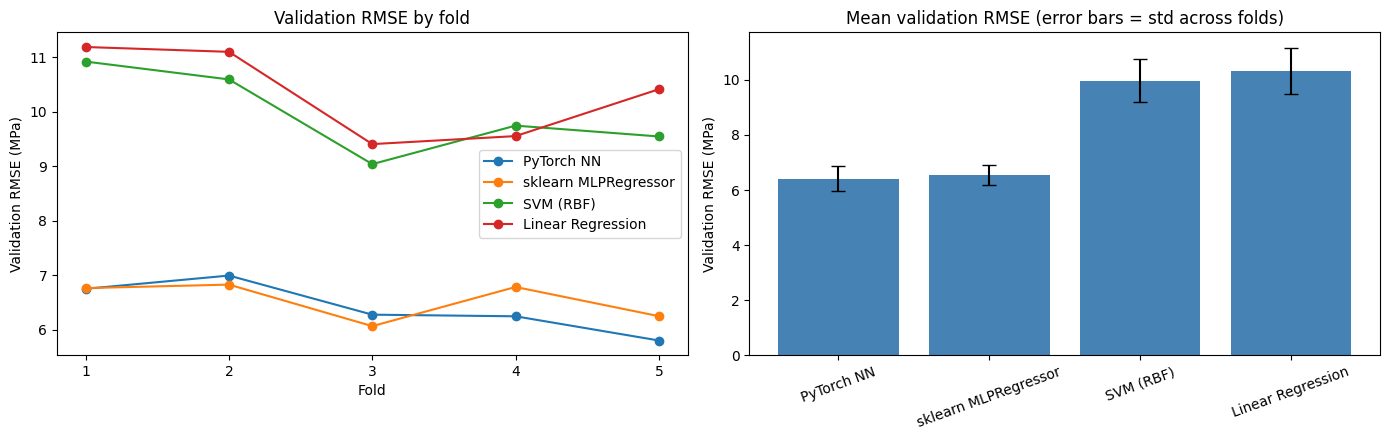

In [13]:
# Compare all models
all_results = {
    "PyTorch NN": nn_results_df,
    "sklearn MLPRegressor": sklearn_results_df,
    "SVM (RBF)": svm_results_df,
    "Linear Regression": linear_results_df,
}
final_comparison = pd.DataFrame({
    name: {
        "Mean Train RMSE": df["Train RMSE"].mean(),
        "Mean Validation RMSE": df["Validation RMSE"].mean(),
        "Std Validation RMSE": df["Validation RMSE"].std(),
        "Mean Validation MSE": df["Validation MSE"].mean(),
    } for name, df in all_results.items()
}).T
print("Five-fold cross-validation (RMSE in MPa; lower is better):")
display(final_comparison.round(3))

# RMSE validation by fold, mean with SE
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, df in all_results.items():
    axes[0].plot(df["Fold"], df["Validation RMSE"], marker="o", label=name)
axes[0].set_xlabel("Fold"); axes[0].set_ylabel("Validation RMSE (MPa)")
axes[0].set_xticks(range(1, 6)); axes[0].set_title("Validation RMSE by fold"); axes[0].legend()

means = final_comparison["Mean Validation RMSE"]
stds = final_comparison["Std Validation RMSE"]
axes[1].bar(means.index, means.values, yerr=stds.values, capsize=5, color="steelblue")
axes[1].set_ylabel("Validation RMSE (MPa)"); axes[1].set_title("Mean validation RMSE (error bars = std across folds)")
plt.setp(axes[1].get_xticklabels(), rotation=20)
plt.tight_layout()
plt.show()

Linear regression performed the worst. Its RMSE was higher than all the other models, and its training and validation errors were relatively close, which could suggest underfitting. Possible explanations include strength increasing with age before leveling off, or the effect of water depending on the amount of cement. These nonlinear relationships and interactions could make it harder for basic linear regression to perform well, although our descriptive plots alone do not establish these effects. 

The neural networks, PyTorch and MLPRegressor did the best with validation RMSEs of 6.41 MPa and 6.54 MPa, respectively. They also had gaps in training and validation RMSEs. This could suggest some overfitting, but the validation error is superior. SVM and Linear Regression had much higher validation errors. A likely reason is that the networks can learn non-linear effects. A linear model can't represent curved relationships, but the two hidden ReLU layers can. The PyTorch network and MLPRegressor are very similar, which can be expected because they have the same optimizer, learning rate, batch size, epochs, and folds. Linear regression and SVM both had relatively small gaps between their training and validation errors, which could suggest underfitting. However, the SVM uses an RBF kernel, meaning it can learn nonlinear relationships, unlike basic linear regression. Its worse performance may be due to its default settings, since we did not tune the model. 

## 6. Collaboration Reflection (5 points)
As a group, identify one specific challenge or inefficiency you encountered while working on this lab. In 3–5 sentences:

Briefly describe what happened and how it affected your work.
Identify one concrete action your group will take to avoid or better manage this issue in the next lab.
If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

One challenge our group ran into was making sure all of our models were being evaluated the same way, especially since we were working on different sections. While reviewing the scikit-learn model, we noticed an indentation mistake that caused it to evaluate only one fold instead of all five, which threw off our initial results. After fixing this, we went back through the code to make sure the models were using the same cross-validation splits and preprocessing steps. For the next lab, we plan to establish a few expected outputs for each section ahead of time, so we can more easily catch issues like missing folds or inconsistent results as we work.